# Issue #296 — candidate-warm-start expert mixture

This notebook rebuilds the matched expert panel, trains the chronological
expert gate, applies the frozen validation fallback, and presents the 2023
CNY100,000 issue-level capital paths. The runner refuses to open 2024+ rows.

Primary conclusion: **NO_PROMOTION**. The raw warm-start ensemble is positive
for only three of five seeds in the 2023 development replay, fails 2022
validation, trails neutral and identity-shuffled controls, and every seed is
negative after removing its largest issue. The implementation safety constraint
therefore falls back to the frozen static control before the 2023 path is read.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

from issue296.experiment import run_experiment

ROOT = Path.cwd()
OUTPUT = ROOT / "results/issue-296"
decision = run_experiment(ROOT, OUTPUT)
decision

{'issue': 296,
 'development_only': True,
 'sealed_source_rows': '2024+ not opened',
 'source_projection_note': 'the model runner consumes committed 2019-2023 projections only; the PI preprocessing session inspected aggregate source files to create them',
 'candidate_identity_warning': 'candidate identities are historically outcome-informed priors; 2023 is a development replay, not an unbiased held-out result',
 'cross_expert_identity_status': 'aggregated source ledgers do not expose a common ticket-identity namespace; exact cross-expert duplicate consolidation is unverified and promotion is barred',
 'tax_adjusted_status': 'not recomputed in exploration mode; primary evidence is pre-tax and the policy is not promoted',
 'train_years': [2019, 2020, 2021],
 'validation_year': 2022,
 'test_year': 2023,
 'expert_ids': ['FULL_CONTROL',
  'SMOOTH_M512',
  'Q_TAIL_M192',
  'Q_WOR_M64',
  'DIVERGENCE_Z100_K1',
  'RARE_LOGIT_TOP64'],
 'static_allocation': {'FULL_CONTROL': 1.6971951589238815e-1

## Frozen expert inventory and support

In [2]:
registry = pd.read_csv(OUTPUT / "expert_registry.csv")
panel = pd.read_csv(OUTPUT / "matched_expert_panel.csv")
display(registry)
display(panel.groupby("expert_id").agg(
    calendar_issues=("issue", "size"),
    available_issues=("available", "sum"),
    active_issues=("stake_unit_cny", lambda values: int((values > 0).sum())),
).reset_index())

,expert_id,source_issue,source_policy,role,training_status,estimand
0,FULL_CONTROL,176,BEST_FULL_FULL,control,ELIGIBLE,REALIZED_POLICY
1,SMOOTH_M512,176,MODEL_SOURCE_MODEL_CAP1_M512,smooth_core,ELIGIBLE,REALIZED_POLICY
2,Q_TAIL_M192,176,Q_SOURCE_Q_TOP_MASS_M192,convex_tail,ELIGIBLE,REALIZED_POLICY
3,Q_WOR_M64,151,Q_INFORMED_WOR_DISTINCT/M64,diversified_tail,ELIGIBLE,NUISANCE_SEED_MEAN
4,DIVERGENCE_Z100_K1,190,DP_5970cc7b2874743a5698,sparse_direction,ELIGIBLE,REALIZED_POLICY
5,RARE_LOGIT_TOP64,291,DATA_LOGIT_RIDGE/DIRECT_PNL/Top64,rare_jackpot,ELIGIBLE,REALIZED_POLICY
6,N7_K16_WR,292,N7_K16_WEIGHTED_WR,candidate_only,SUMMARY_ONLY_INELIGIBLE,NO_TRUSTED_ISSUE_PATH


,expert_id,calendar_issues,available_issues,active_issues
0,DIVERGENCE_Z100_K1,269,227,56
1,FULL_CONTROL,269,227,106
2,Q_TAIL_M192,269,227,171
3,Q_WOR_M64,269,227,171
4,RARE_LOGIT_TOP64,269,269,269
5,SMOOTH_M512,269,227,131


`N7_K16_WR` is intentionally registry-only: #292 supplied a
summary distribution but no trusted issue path. A missing ledger row is kept
unavailable; a real zero-stake row remains a valid frozen NO_BET.

## Chronological performance

In [3]:
period = pd.read_csv(OUTPUT / "policy_period_summary.csv")
focus = [
    "CONTROL_CASH_NO_BET", "CONTROL_FULL_CONTROL", "STATIC_TRAIN_LOG_GROWTH",
    "RIDGE_CONTROL", "candidate_warm", "neutral", "identity_shuffled",
    "candidate_warm_guarded",
]
columns = [
    "condition", "period", "terminal_capital_cny", "capital_growth_pct",
    "turnover_roi_pct", "max_drawdown_pct", "longest_losing_issue_streak",
    "rolling_10_loss_probability", "ex_largest_pnl_cny",
]
display(period[period.condition.isin(focus)][columns])

,condition,period,terminal_capital_cny,capital_growth_pct,turnover_roi_pct,max_drawdown_pct,longest_losing_issue_streak,rolling_10_loss_probability,ex_largest_pnl_cny
0,CONTROL_FULL_CONTROL,TRAIN_2019_2021,1.897007e+03,-9.810299e+01,-18.384154,98.948043,2,0.165517,-1.784341e+05
1,CONTROL_FULL_CONTROL,VALIDATION_2022,3.604334e+03,-9.639567e+01,-14.037154,96.999330,2,0.509434,-1.737668e+05
2,CONTROL_FULL_CONTROL,TEST_2023,2.515184e+03,-9.748482e+01,-63.678109,97.484816,3,0.318182,-9.748482e+04
18,CONTROL_CASH_NO_BET,TRAIN_2019_2021,1.000000e+05,0.000000e+00,0.000000,0.000000,0,0.000000,0.000000e+00
19,CONTROL_CASH_NO_BET,VALIDATION_2022,1.000000e+05,0.000000e+00,0.000000,0.000000,0,0.000000,0.000000e+00
20,CONTROL_CASH_NO_BET,TEST_2023,1.000000e+05,0.000000e+00,0.000000,0.000000,0,0.000000,0.000000e+00
21,STATIC_TRAIN_LOG_GROWTH,TRAIN_2019_2021,2.173787e+06,2.073787e+03,8.830963,89.813023,39,0.620690,-4.364827e+06
22,STATIC_TRAIN_LOG_GROWTH,VALIDATION_2022,1.815140e+05,8.151395e+01,33.819849,59.475087,19,0.811321,-1.714072e+05
23,STATIC_TRAIN_LOG_GROWTH,TEST_2023,1.041429e+05,4.142898e+00,2.397510,52.700411,19,0.659091,-9.801937e+04
24,RIDGE_CONTROL,TRAIN_2019_2021,1.600000e+02,-9.984000e+01,-100.000000,99.840000,5,0.034483,-9.984000e+04


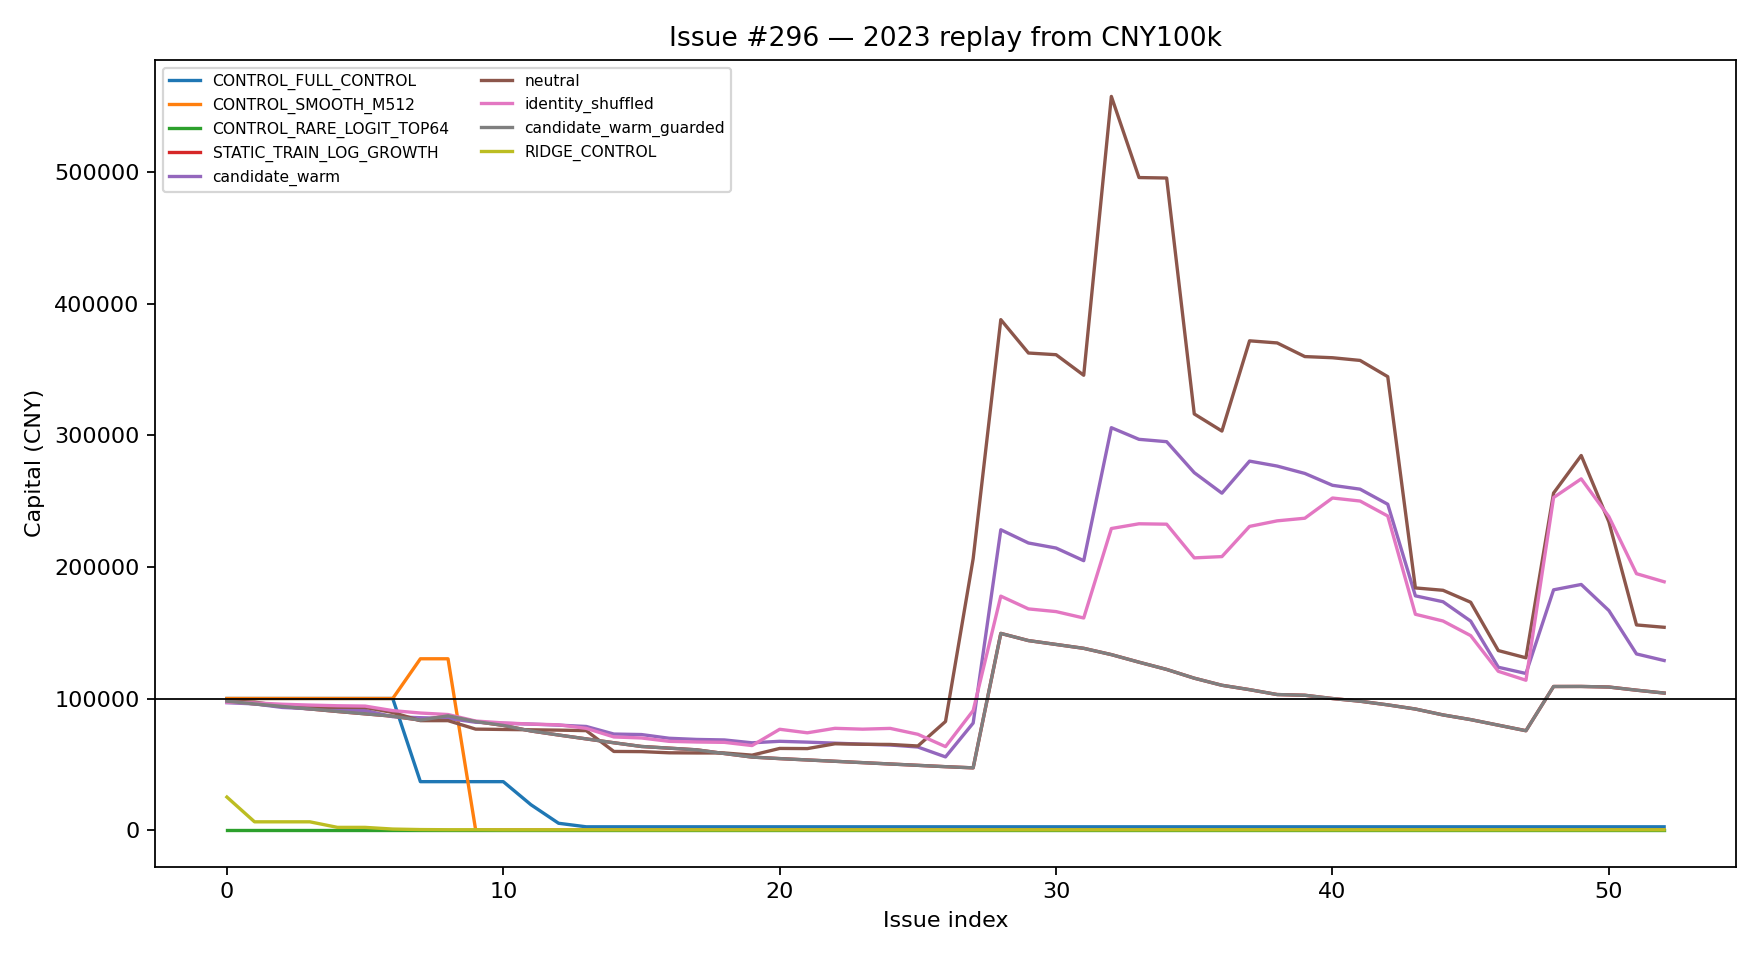

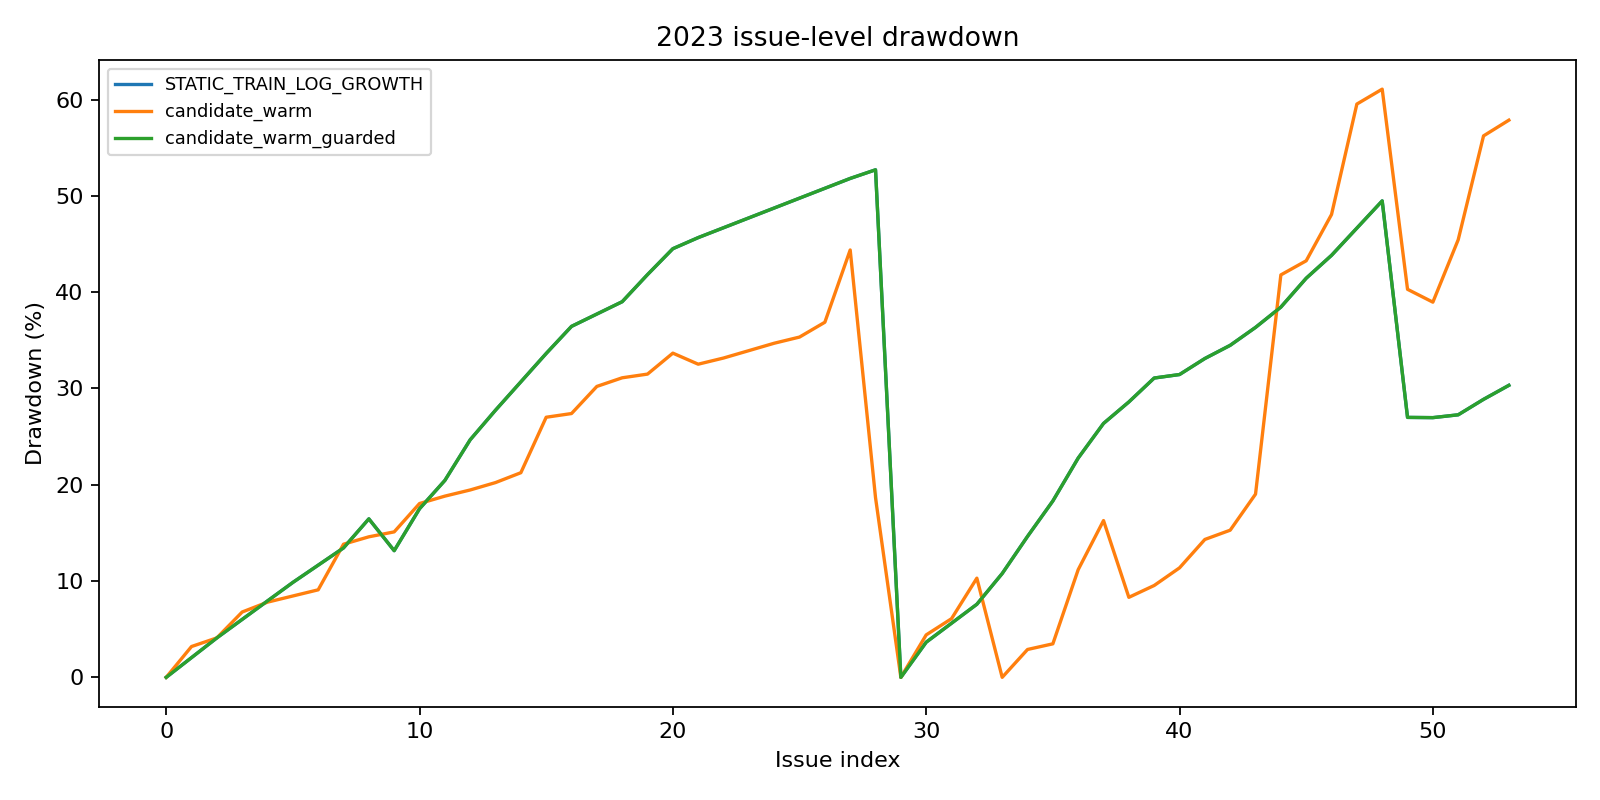

In [4]:
display(Image(filename=str(OUTPUT / "capital_paths_2023.png")))
display(Image(filename=str(OUTPUT / "drawdown_2023.png")))

## Seed stability and validation fallback

In [5]:
seed = pd.read_csv(OUTPUT / "seed_summary_2023.csv")
display(seed[[
    "model_condition", "model_seed", "capital_growth_pct",
    "max_drawdown_pct", "ex_largest_pnl_cny",
]])
display(pd.read_csv(OUTPUT / "validation_fallback_receipts.csv"))

,model_condition,model_seed,capital_growth_pct,max_drawdown_pct,ex_largest_pnl_cny
0,candidate_warm,296001,41.971853,63.943631,-136819.437940
1,candidate_warm,296002,17.388104,60.716761,-113963.382487
2,candidate_warm,296003,-6.375817,62.676319,-133631.304122
3,candidate_warm,296004,-35.802055,76.921878,-134126.932492
4,candidate_warm,296005,71.733082,61.371976,-87251.418119
5,neutral,296001,-26.105378,88.495830,-342924.929513
6,neutral,296002,81.388986,63.100540,-80894.476561
7,neutral,296003,-60.845973,89.761202,-234410.750711
8,neutral,296004,30.109277,85.868863,-328781.351407
9,neutral,296005,155.691365,70.765271,-177558.958416


,condition,decision,learned_validation_capital_cny,baseline_validation_capital_cny,learned_validation_max_drawdown_pct,baseline_validation_max_drawdown_pct
0,candidate_warm_guarded,FROZEN_BASELINE_FALLBACK,61320.954349,181513.951986,76.566733,59.475087
1,neutral_guarded,FROZEN_BASELINE_FALLBACK,7009.764839,181513.951986,94.208000,59.475087
2,identity_shuffled_guarded,FROZEN_BASELINE_FALLBACK,61380.754931,181513.951986,68.864000,59.475087


## What the learned gate allocated

,mean_2023_weight
weight_CASH,0.783071
weight_DIVERGENCE_Z100_K1,0.056486
weight_FULL_CONTROL,0.049076
weight_SMOOTH_M512,0.045443
weight_Q_TAIL_M192,0.029626
weight_RARE_LOGIT_TOP64,0.022550
weight_Q_WOR_M64,0.013748


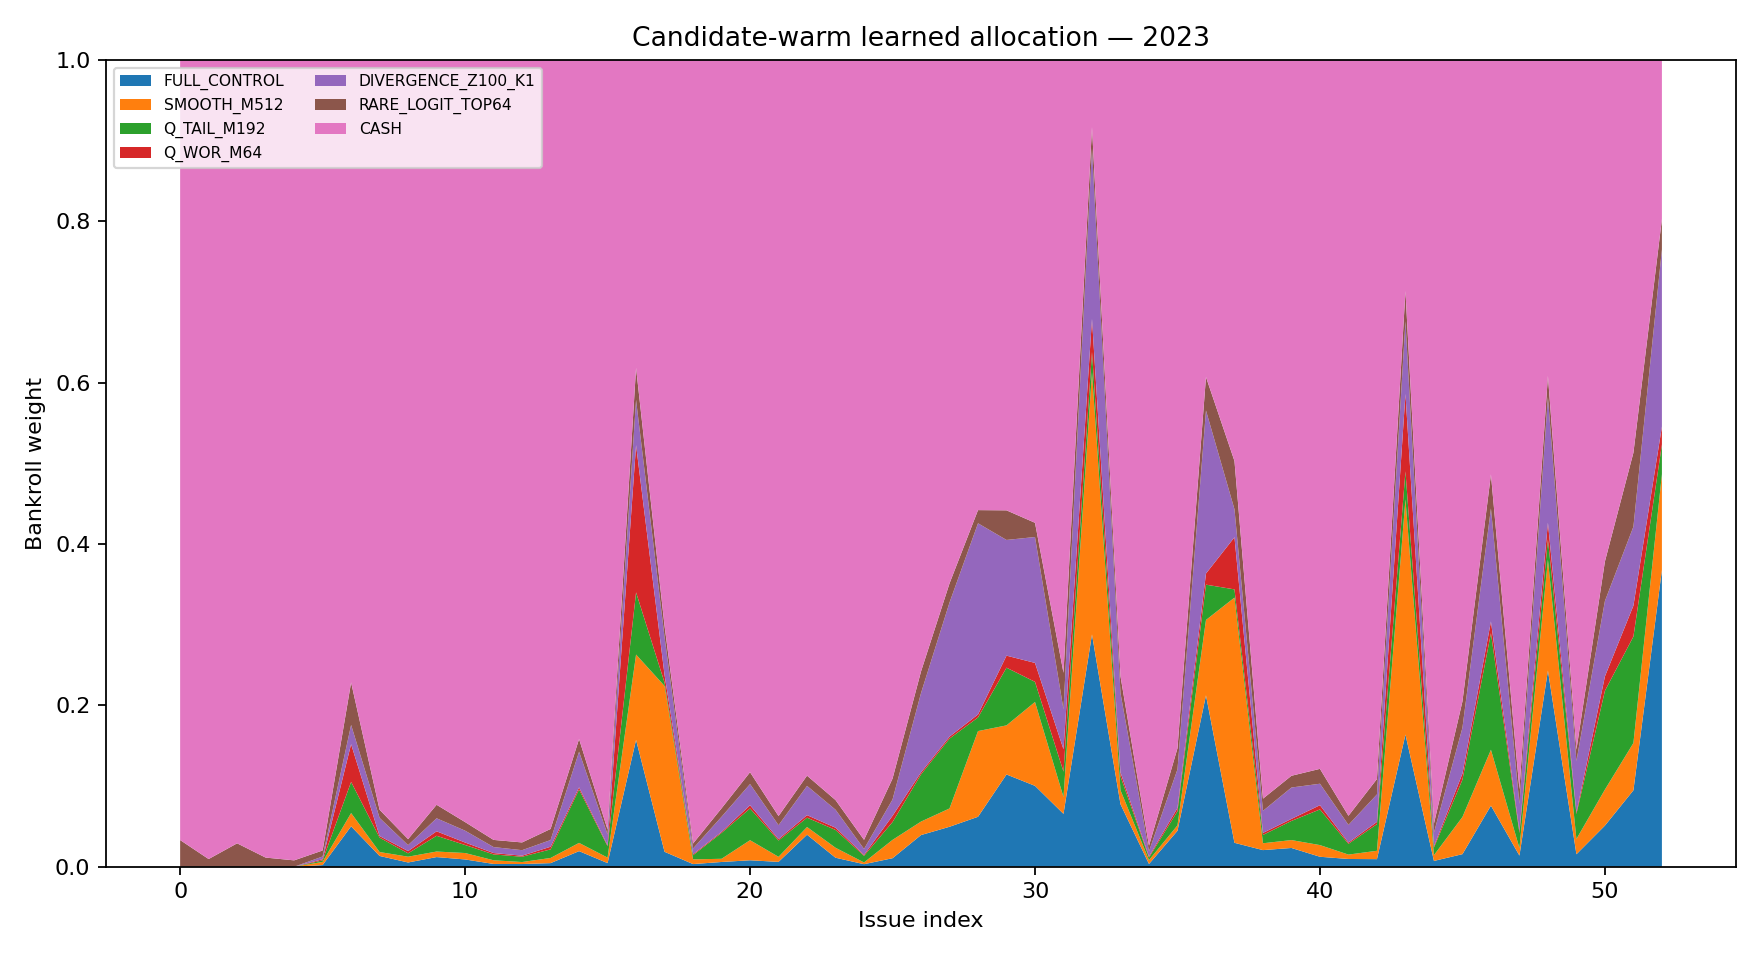

In [6]:
weights = pd.read_csv(OUTPUT / "weights_candidate_warm.csv")
weight_columns = [column for column in weights if column.startswith("weight_")]
display(
    weights[weights.issue_year.eq(2023)][weight_columns]
    .mean().sort_values(ascending=False).rename("mean_2023_weight").to_frame()
)
display(Image(filename=str(OUTPUT / "candidate_warm_weights_2023.png")))

## Static core–tail curve and expert dependence

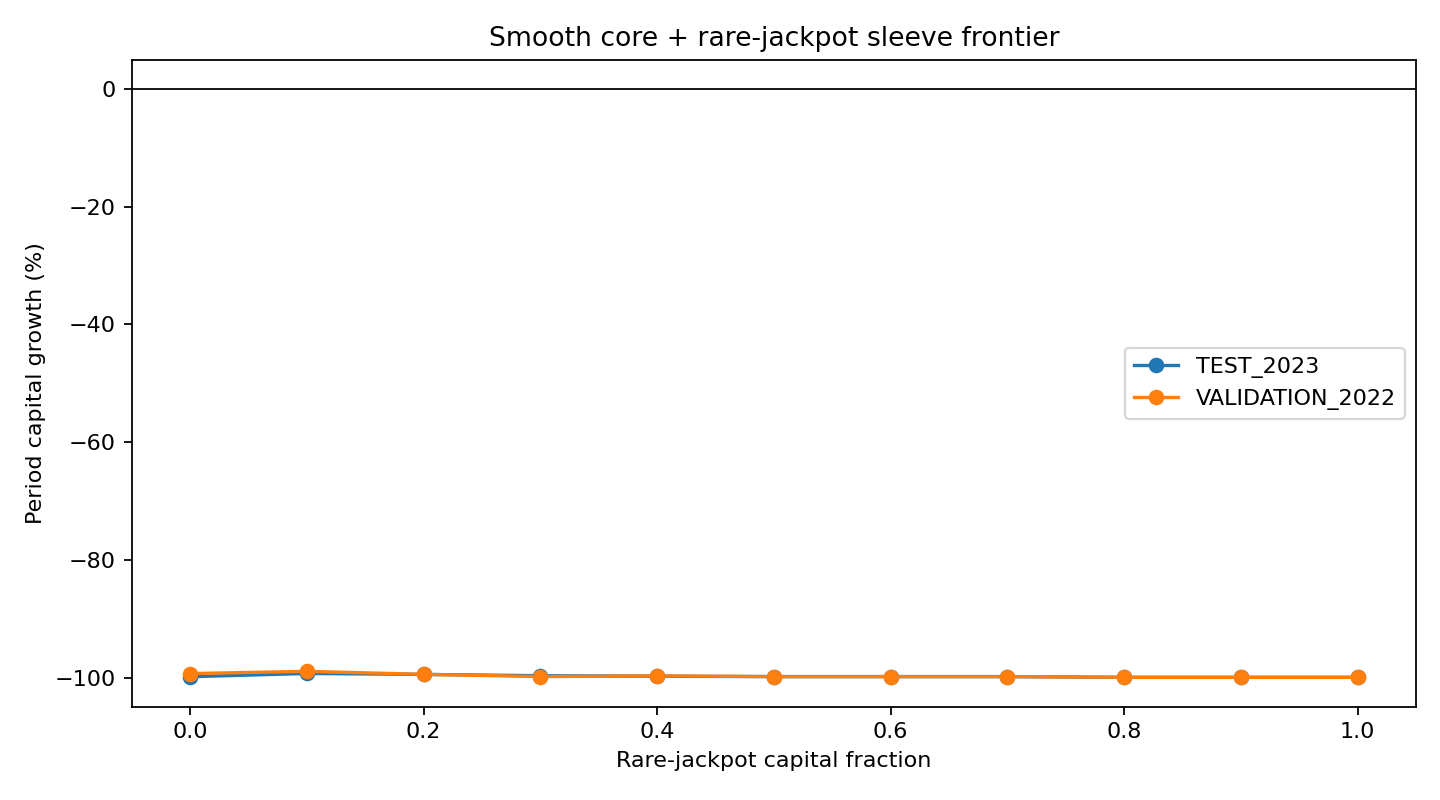

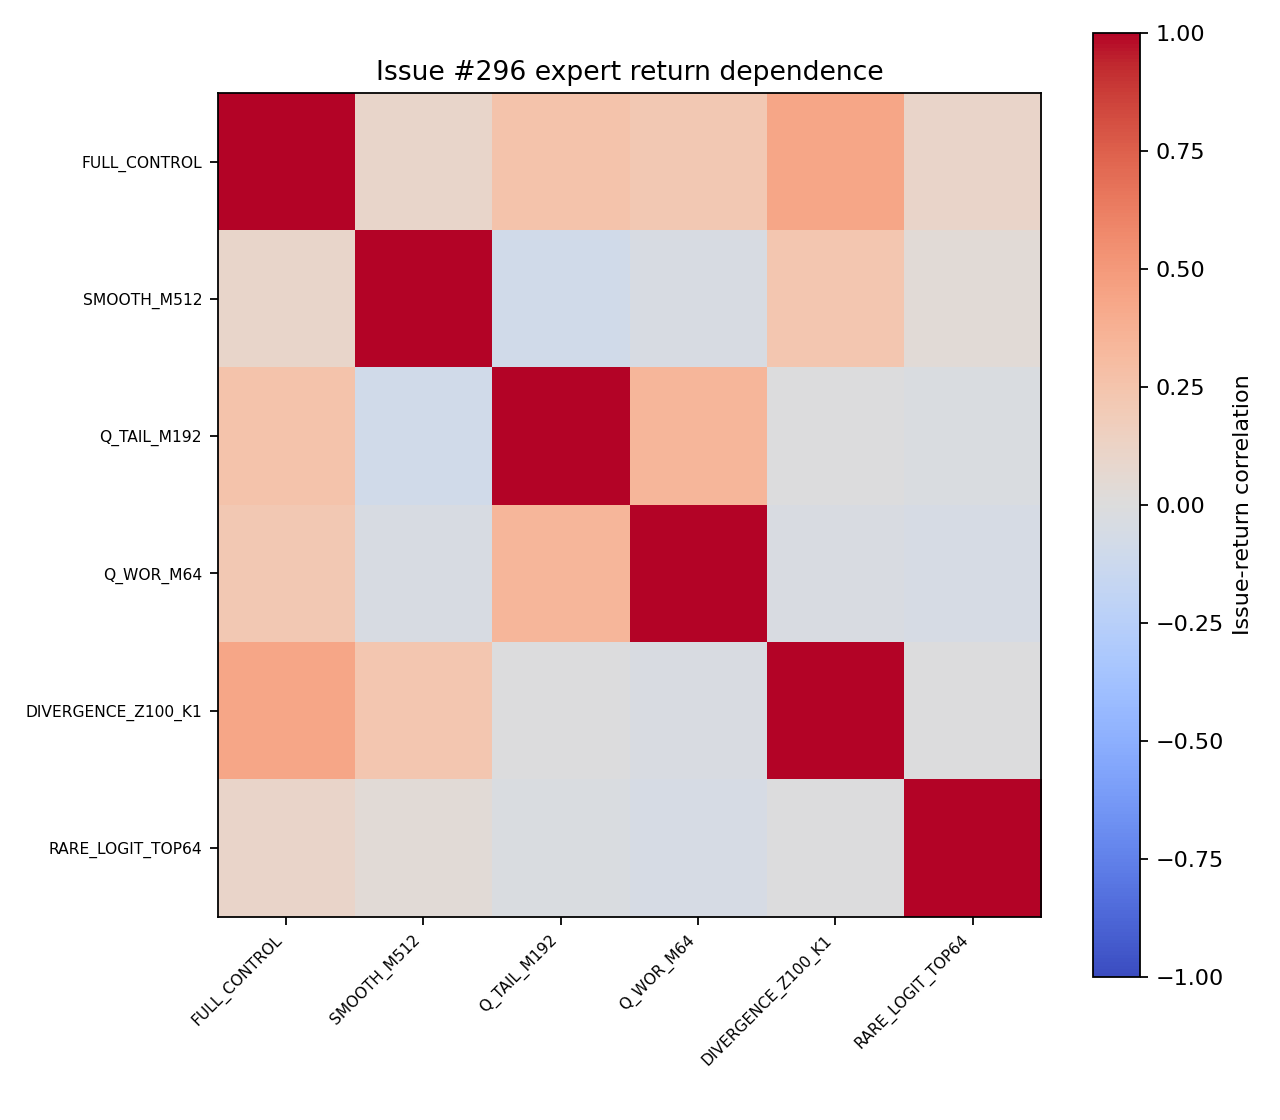

,expert_left,expert_right,return_correlation,joint_loss_rate,joint_positive_rate
13,Q_TAIL_M192,SMOOTH_M512,-0.086297,0.197026,0.011152
23,Q_WOR_M64,RARE_LOGIT_TOP64,-0.049156,0.460967,0.000000
19,Q_WOR_M64,SMOOTH_M512,-0.044323,0.178439,0.066914
27,DIVERGENCE_Z100_K1,Q_WOR_M64,-0.033068,0.081784,0.014870
17,Q_TAIL_M192,RARE_LOGIT_TOP64,-0.030752,0.542751,0.000000
29,DIVERGENCE_Z100_K1,RARE_LOGIT_TOP64,-0.007542,0.107807,0.000000
26,DIVERGENCE_Z100_K1,Q_TAIL_M192,-0.002160,0.096654,0.007435
31,RARE_LOGIT_TOP64,SMOOTH_M512,0.033181,0.252788,0.003717
1,FULL_CONTROL,SMOOTH_M512,0.096084,0.133829,0.055762
5,FULL_CONTROL,RARE_LOGIT_TOP64,0.106732,0.256506,0.007435


In [7]:
display(Image(filename=str(OUTPUT / "core_tail_frontier.png")))
display(Image(filename=str(OUTPUT / "expert_return_correlation.png")))
dependence = pd.read_csv(OUTPUT / "expert_dependence.csv")
display(
    dependence[dependence.expert_left < dependence.expert_right]
    .sort_values("return_correlation")
    .head(10)
)

## Machine decision and reproducibility receipt

In [8]:
display(json.loads((OUTPUT / "decision.json").read_text()))
display(json.loads((OUTPUT / "manifest.json").read_text()))

{'issue': 296,
 'development_only': True,
 'sealed_source_rows': '2024+ not opened',
 'source_projection_note': 'the model runner consumes committed 2019-2023 projections only; the PI preprocessing session inspected aggregate source files to create them',
 'candidate_identity_warning': 'candidate identities are historically outcome-informed priors; 2023 is a development replay, not an unbiased held-out result',
 'cross_expert_identity_status': 'aggregated source ledgers do not expose a common ticket-identity namespace; exact cross-expert duplicate consolidation is unverified and promotion is barred',
 'tax_adjusted_status': 'not recomputed in exploration mode; primary evidence is pre-tax and the policy is not promoted',
 'train_years': [2019, 2020, 2021],
 'validation_year': 2022,
 'test_year': 2023,
 'expert_ids': ['FULL_CONTROL',
  'SMOOTH_M512',
  'Q_TAIL_M192',
  'Q_WOR_M64',
  'DIVERGENCE_Z100_K1',
  'RARE_LOGIT_TOP64'],
 'static_allocation': {'FULL_CONTROL': 1.6971951589238815e-1

{'inputs': {'docs/research/artifacts/issue-291/ranking_issue_paths.csv': 'dac3b77a70ca0232781b5cc16a5c93e7e250af0aa5d6251357c6491f7a1e12e1',
  'docs/research/artifacts/issue-292/shortlist_seed_summary.csv': '4c52ab9c02f828a3a5bde15d50f2e4083d320288d08502087f2f8819eac3a6ce',
  'evidence/bj296_expert_sources_v1/issue151_wor_m64_2019_2023.csv': 'a2d2d50e190cd53fbb9c2e06bd57cf97fd1069ac50cd27a8fb8a961d9942cdd5',
  'evidence/bj296_expert_sources_v1/issue176_experts_2019_2023.csv': '9b25bfe97d0020a5e64d5237b9b39c298ad06e7495b4ed504b43fbf1a144d48f',
  'evidence/bj296_expert_sources_v1/issue190_z100_k1_2019_2023.csv': 'bc34ee07f4adc4122311fa69f9e68dd5e42b91963dd62627db73e8993baff5d7',
  'evidence/bj296_expert_sources_v1/issue209_features_2019_2023.csv': '8b1b66e085714b434eb144bab7305ae6cdc3f1310981825ee27d931ee2dffba2',
  'evidence/bj296_expert_sources_v1/manifest.json': '40ec29e54acbc5bc7be0545c3c716446d16a6ba1949c83ad7460f5623eeed8d4'},
 'issue': 296,
 'outputs': {'baseline_ladder.csv': '6c4